In [1]:
import pandas as pd
import os
import json
import numpy as np
import pandas as pd
import SimpleITK as sitk
from radiomics import featureextractor
from datetime import datetime
import warnings
from pathlib import Path
import logging
import matplotlib.pyplot as plt
from IPython.display import clear_output
from shutil import copyfile


# Block 1: From Aligned Images to Features

UX goal: allow clinical/technical users to load ADC, T2, and lesion mask data and obtain a feature table ready for classification.

# Block1: images_from_aligned_images (UPDATE 29/April)

In [2]:
TYPE_IMAGE = 'standard'

In [3]:
subjs_aligned = np.sort(os.listdir('../SNIPPET_from_dicom_to_aligned_images/data'))[1:]

#### NAME OF THE NEW SUBJECT TO BE PROCESSED

### NOW WE HAVE STORED [subj_0, subj_1, subj_2]

### REQUIRED FOLDERS:
# subj id, i.e., subj_0
# data/subj_0/images (ADC and T2 in nifty format)
# data/subj_0/labels (segmentation in nifty format)
# data/subj_0/features/clinical (psa density in csv format)

subj = subjs_aligned[0]
print(subj)

from pathlib import Path

base = Path("../SNIPPET_from_dicom_to_aligned_images/data") / subj

im_path = sorted(
    str(p) for p in (base / "images").iterdir()
    if p.name.endswith(".nii.gz")
)

# Serve solo se vuoi caricare anche le maschere presenti in quella cartella
segm_path = sorted(
    str(p) for p in (base / "labels").iterdir()
    if p.name.endswith(".nii.gz")
)

### IMPORT IMAGES
#im_path =  '../SNIPPET_from_dicom_to_aligned_images/data/' + subj + '/' + 'images' + '/' + np.array(os.listdir(f'../SNIPPET_from_dicom_to_aligned_images/data/{subj}/images')).astype(str)
appo = []
for im in im_path:
    if 'nii.gz' in im:
        appo.append(im)
im_path = sorted(appo)

### IMPORT SEGMENTATIONS
#segm_path =  '../SNIPPET_from_dicom_to_aligned_images/data/' + subj + '/' + 'labels' + '/' + np.array(os.listdir(f'../SNIPPET_from_dicom_to_aligned_images/data/{subj}/labels')).astype(str)
appo = []
for im in segm_path:
    if 'nii.gz' in im:
        appo.append(im)
segm_path = sorted(appo)
df = pd.DataFrame(np.append(im_path, segm_path))


### CONSTRUCT DATAFRAME
df = df.transpose().rename(columns = {0: 'images_ADC', 1: 'images_T2', 2: 'segm'})

df['Subject']= subj


### IMPORT CLINICAL DATA
psa_density = pd.read_csv('../SNIPPET_from_dicom_to_aligned_images/data/' + df['Subject'].iloc[0] + "/features/clinical/psa_density.csv" )['psa_density']

PRISM 001


In [5]:
subjs_aligned

array(['PRISM 001', 'PRISM 002', 'PRISM 125', 'PRISM 126', 'PRISM 127',
       'PRISM 128', 'PRISM 129', 'PRISM 130', 'PRISM 131', 'PRISM 132',
       'PRISM 133', 'PRISM 134'], dtype='<U9')

In [6]:
df['images_ADC'][0]

'..\\SNIPPET_from_dicom_to_aligned_images\\data\\PRISM 001\\images\\0000.nii.gz'

# TRIAL WITH AUTOMATIC SEGMENTATION

In [12]:
TYPE_IMAGE = 'automatic_segmentation'

In [16]:
from pathlib import Path
import pandas as pd

path = Path("../SNIPPET_automatic_segmentation")

subjs_aligned = sorted([p.name for p in path.iterdir() if p.is_dir()])
subj = subjs_aligned[0]
print(subj)
# images
images = sorted((path / subj / "images").glob("*.nii.gz"))

t2_path = [p for p in images if "_0001" in p.name][0]
adc_path  = [p for p in images if "_0000" in p.name][0]

# segmentations
segm_paths = sorted((path / subj / "labels").glob("*.nii.gz"))

# clinical
psa_path = path / subj / "features" / "clinical" / "psa_density.csv"
psa_density = pd.read_csv(psa_path)["psa_density"].iloc[0]

# final dataframe: one row per segmentation
df = pd.DataFrame({
    "Subject": subj,
    "images_T2": str(t2_path),
    "images_ADC": str(adc_path),
    "segm": [str(p) for p in segm_paths],
    "psa_density": psa_density,
})

df

ext0000


,Subject,images_T2,images_ADC,segm,psa_density
0,ext0000,..\automatic_segmentation\ext0000\images\ext00...,..\automatic_segmentation\ext0000\images\ext00...,..\automatic_segmentation\ext0000\labels\ext00...,0.122364
1,ext0000,..\automatic_segmentation\ext0000\images\ext00...,..\automatic_segmentation\ext0000\images\ext00...,..\automatic_segmentation\ext0000\labels\ext00...,0.122364


## Input Check and Preview

What the UI needs:
- Subject selection (e.g., subj_0)
- ADC, T2, segm files in .nii.gz format
- Quick shape consistency check

What to display:
- Slice preview with mask overlay
- Check result: are the images aligned properly? if yes, compute features

In [17]:
df.shape[0]

2

(320, 320, 27)
(320, 320, 27)
(320, 320, 27)


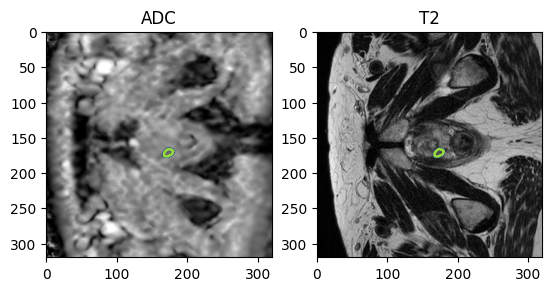

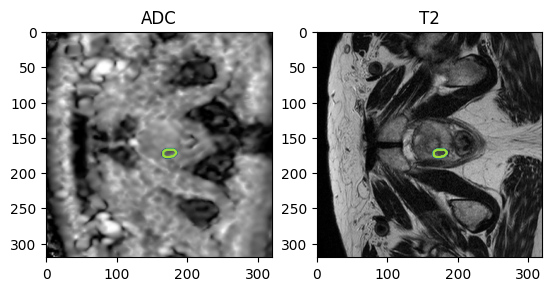

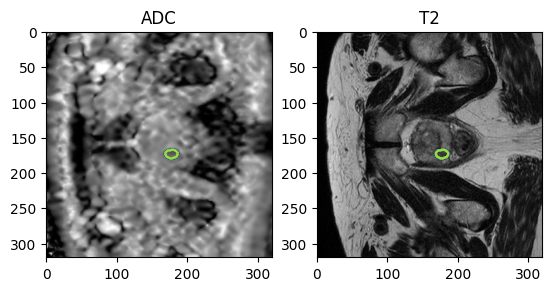

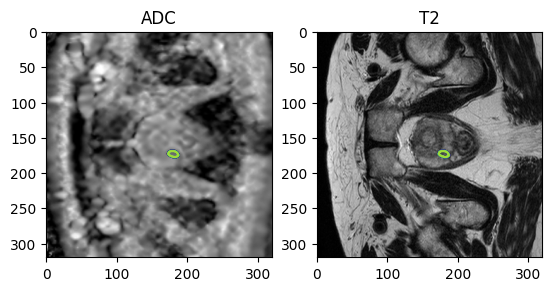

(320, 320, 27)
(320, 320, 27)
(320, 320, 27)


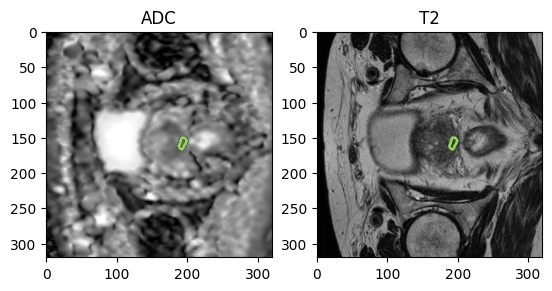

In [18]:
import nibabel as nib

for j in range(df.shape[0]):

    segm = nib.load(df['segm'][j]).get_fdata()
    im_ADC = nib.load(df['images_ADC'][j]).get_fdata()
    im_T2 = nib.load(df['images_T2'][j]).get_fdata()

    print(segm.shape)
    print(im_ADC.shape)
    print(im_T2.shape)


    for i in range(segm.shape[2]):
        
        if segm[:,:,i].sum() > 0:
            
            fig, ax = plt.subplots(1,2)

            
            ax[0].set_title('ADC')
            ax[0].imshow(im_ADC[:,:,i], cmap='gray')
            ax[0].contour(segm[:,:,i])
            ax[1].set_title('T2')
            ax[1].imshow(im_T2[:,:,i], cmap='gray')
            ax[1].contour(segm[:,:,i])
            plt.show()

In [19]:
df

,Subject,images_T2,images_ADC,segm,psa_density
0,ext0000,..\automatic_segmentation\ext0000\images\ext00...,..\automatic_segmentation\ext0000\images\ext00...,..\automatic_segmentation\ext0000\labels\ext00...,0.122364
1,ext0000,..\automatic_segmentation\ext0000\images\ext00...,..\automatic_segmentation\ext0000\images\ext00...,..\automatic_segmentation\ext0000\labels\ext00...,0.122364


## Feature Extraction and Expected Outputs

Functional outputs to expose in the UX:
- df.csv: final feature vector per subject
- quality report: extraction status for T2/ADC
- outlier stats: clipping and robustness indicators

Recommended UX states:
1. Queued
2. Processing
3. Completed with warning
4. Completed
5. Failed (with readable technical cause)

Output contract from Block 1:
- One tabular row with numeric features + psa_density
- Subject preserved for traceability

In [20]:
from pathlib import Path
import os
import json
from datetime import datetime
from shutil import copyfile
import numpy as np
import pandas as pd
import SimpleITK as sitk
from radiomics import featureextractor
import warnings
import logging
import matplotlib.pyplot as plt
from IPython.display import clear_output

normalization_options = ["lesion"]  # "ring", "lesion", "none"
appo = []

for norm in normalization_options:

    # ------------------------------- CONFIG --------------------------------
    print("⚙️ Feature extraction configuration:")

    T2_COL = "images_T2"
    ADC_COL = "images_ADC"
    LESION_MASK_COL = "segm"

    MIN_PIXEL_T2 = 1
    MIN_PIXEL_ADC = 1

    USE_RESAMPLING_TO_COMMON_GRID_INPLANE = True
    TARGET_SPACING_XY = [1, 1]

    USE_SOFT_MASK_FALLBACK = True
    SOFT_MASK_THRESH = 0.2

    USE_N4_T2 = False

    USE_BINCOUNT = True
    BIN_COUNT = 16
    BIN_WIDTH = 0.1

    USE_WAVELET = False
    START_FROM = 0

    # ------------------------------------------------
    # REFERENCE REGION PER MODALITY
    # choices: "ring", "lesion", "none"
    # ------------------------------------------------
    T2_NORM_MODE = norm
    ADC_NORM_MODE = norm

    # used only if norm_mode == "lesion"
    # choices: "original", "updated"
    LESION_NORM_SOURCE = "original"

    # ------------------------------------------------
    # NORMALIZATION TRANSFORM PER MODALITY
    # choices:
    #   "zscore"
    #   "minmax"
    #   "maxscale"
    #   "pmaxscale"
    #   "none"
    #   "mad_zscore"
    #   "iqr_zscore"
    # ------------------------------------------------
    T2_NORM_TRANSFORM = "iqr_zscore"
    ADC_NORM_TRANSFORM = "iqr_zscore"

    # ------------------------------------------------
    # DIMENSION OF STATISTICS / APPLICATION
    # choices: "2D", "3D"
    # ------------------------------------------------
    T2_NORM_STATS_DIM = "2D"
    ADC_NORM_STATS_DIM = "2D"

    T2_NORM_APPLY_DIM = "2D"
    ADC_NORM_APPLY_DIM = "2D"

    PMAX_PERCENTILE = 99.0
    MINMAX_PERCENTILES = (2, 98)

    MIN_REF_VOXELS = 20

    # normalization ring (if used as ref region)
    RING_INNER_MM = 0.0
    RING_OUTER_MM = 4.0

    ADC_PERC_RANGE = (0, 100)
    T2_PERC_RANGE = (0, 100)

    USE_COMMON_CROP = False
    COMMON_FOV_MM = (80.0, 80.0, 24.0)

    BLACK_PIXEL_THR_FRAC = 0.20

    SAVE_QC = False
    QC_OUTPUT_DIR = "QC_radiomics_pngs"

    USE_LARGEST_SLICE_ONLY = True
    MIN_PIXELS_IN_LARGEST_SLICE = 1

    SAVE_ROOT = Path("radiomics_iterative_save_2DlargestSlice_v0_noProstate_withResample")
    PER_SUBJECT_DIR = SAVE_ROOT / "per_subject"
    PER_MODALITY_DIR = SAVE_ROOT / "per_modality"
    PER_QUALITY_DIR = SAVE_ROOT / "per_quality"
    PER_OUTLIER_DIR = SAVE_ROOT / "per_outlier"
    LOG_DIR = SAVE_ROOT / "logs"

    AUTO_SKIP_ALREADY_DONE = False
    FORCE_OVERWRITE_SUBJECT = True

    # ----------------------- PyRadiomics Parameters -----------------------
    base_setting = {
        "normalize": False,
        "force2D": True,
        "force2Ddimension": 0,
    }

    if USE_BINCOUNT:
        base_setting["binCount"] = BIN_COUNT
    else:
        base_setting["binWidth"] = BIN_WIDTH

    image_types = {"Original": {}}
    if USE_WAVELET:
        image_types["Wavelet"] = {}

    params = {
        "padDistance": 5,
        "correctMask": True,
        "additionalInfo": True,
        "enableCExtensions": True,
        "imageType": image_types,
        "setting": base_setting,
    }

    logging.getLogger("radiomics").setLevel(logging.ERROR)
    extractor = featureextractor.RadiomicsFeatureExtractor(**params)

    extractor.disableAllFeatures()
    extractor.enableFeatureClassByName("firstorder")
    extractor.enableFeatureClassByName("shape")
    extractor.enableFeatureClassByName("glcm")
    extractor.enableFeatureClassByName("glrlm")
    extractor.enableFeatureClassByName("glszm")
    extractor.enableFeatureClassByName("gldm")
    extractor.enableFeatureClassByName("ngtdm")

    print("✅ PyRadiomics extractor configured")

    RUN_CONFIG = {
        "T2_COL": T2_COL,
        "ADC_COL": ADC_COL,
        "LESION_MASK_COL": LESION_MASK_COL,
        "MIN_PIXEL_T2": MIN_PIXEL_T2,
        "MIN_PIXEL_ADC": MIN_PIXEL_ADC,
        "USE_RESAMPLING_TO_COMMON_GRID_INPLANE": USE_RESAMPLING_TO_COMMON_GRID_INPLANE,
        "TARGET_SPACING_XY": TARGET_SPACING_XY,
        "USE_SOFT_MASK_FALLBACK": USE_SOFT_MASK_FALLBACK,
        "SOFT_MASK_THRESH": SOFT_MASK_THRESH,
        "USE_N4_T2": USE_N4_T2,
        "USE_BINCOUNT": USE_BINCOUNT,
        "BIN_COUNT": BIN_COUNT,
        "BIN_WIDTH": BIN_WIDTH,
        "USE_WAVELET": USE_WAVELET,
        "START_FROM": START_FROM,
        "T2_NORM_MODE": T2_NORM_MODE,
        "ADC_NORM_MODE": ADC_NORM_MODE,
        "LESION_NORM_SOURCE": LESION_NORM_SOURCE,
        "T2_NORM_TRANSFORM": T2_NORM_TRANSFORM,
        "ADC_NORM_TRANSFORM": ADC_NORM_TRANSFORM,
        "T2_NORM_STATS_DIM": T2_NORM_STATS_DIM,
        "ADC_NORM_STATS_DIM": ADC_NORM_STATS_DIM,
        "T2_NORM_APPLY_DIM": T2_NORM_APPLY_DIM,
        "ADC_NORM_APPLY_DIM": ADC_NORM_APPLY_DIM,
        "PMAX_PERCENTILE": PMAX_PERCENTILE,
        "MINMAX_PERCENTILES": MINMAX_PERCENTILES,
        "MIN_REF_VOXELS": MIN_REF_VOXELS,
        "RING_INNER_MM": RING_INNER_MM,
        "RING_OUTER_MM": RING_OUTER_MM,
        "ADC_PERC_RANGE": ADC_PERC_RANGE,
        "T2_PERC_RANGE": T2_PERC_RANGE,
        "USE_COMMON_CROP": USE_COMMON_CROP,
        "COMMON_FOV_MM": COMMON_FOV_MM,
        "BLACK_PIXEL_THR_FRAC": BLACK_PIXEL_THR_FRAC,
        "SAVE_QC": SAVE_QC,
        "QC_OUTPUT_DIR": QC_OUTPUT_DIR,
        "USE_LARGEST_SLICE_ONLY": USE_LARGEST_SLICE_ONLY,
        "MIN_PIXELS_IN_LARGEST_SLICE": MIN_PIXELS_IN_LARGEST_SLICE,
        "SAVE_ROOT": str(SAVE_ROOT),
        "AUTO_SKIP_ALREADY_DONE": AUTO_SKIP_ALREADY_DONE,
        "FORCE_OVERWRITE_SUBJECT": FORCE_OVERWRITE_SUBJECT,
        "PYRADIOMICS_base_setting": base_setting,
        "PYRADIOMICS_image_types": image_types,
        "PYRADIOMICS_params": params,
        "PYRADIOMICS_enabled_feature_classes": [
            "firstorder", "shape", "glcm", "glrlm", "glszm", "gldm", "ngtdm"
        ],
    }

    # ------------------------------------ UTILS ------------------------------------

    def ensure_dir(path):
        Path(path).mkdir(parents=True, exist_ok=True)

    for d in [SAVE_ROOT, PER_SUBJECT_DIR, PER_MODALITY_DIR, PER_QUALITY_DIR, PER_OUTLIER_DIR, LOG_DIR]:
        ensure_dir(d)

    if SAVE_QC:
        ensure_dir(QC_OUTPUT_DIR)

    def save_json_pretty(obj, out_path):
        out_path = Path(out_path)
        with open(out_path, "w") as f:
            json.dump(obj, f, indent=2, default=str)

    def build_run_readme_text(run_config, total_subjects=None):
        lines = []
        lines.append("# Radiomics extraction run")
        lines.append("")
        lines.append(f"Generated on: {datetime.now().isoformat()}")
        lines.append("")
        lines.append("## Summary")
        lines.append("")
        lines.append("This folder contains the outputs of one radiomics extraction run.")
        lines.append("The configuration below stores the exact flags used for reproducibility.")
        lines.append("")
        if total_subjects is not None:
            lines.append(f"- Number of subjects: `{total_subjects}`")
        lines.append(f"- Largest slice only: `{run_config['USE_LARGEST_SLICE_ONLY']}`")
        lines.append(f"- T2 normalization: `{run_config['T2_NORM_MODE']}` + `{run_config['T2_NORM_TRANSFORM']}`")
        lines.append(f"- ADC normalization: `{run_config['ADC_NORM_MODE']}` + `{run_config['ADC_NORM_TRANSFORM']}`")
        lines.append(f"- T2 stats/apply dims: `{run_config['T2_NORM_STATS_DIM']}` / `{run_config['T2_NORM_APPLY_DIM']}`")
        lines.append(f"- ADC stats/apply dims: `{run_config['ADC_NORM_STATS_DIM']}` / `{run_config['ADC_NORM_APPLY_DIM']}`")
        lines.append(f"- In-plane resampling: `{run_config['USE_RESAMPLING_TO_COMMON_GRID_INPLANE']}`")
        lines.append(f"- Target spacing XY: `{run_config['TARGET_SPACING_XY']}`")
        lines.append(f"- Common crop: `{run_config['USE_COMMON_CROP']}`")
        lines.append(f"- T2 clipping percentiles: `{run_config['T2_PERC_RANGE']}`")
        lines.append(f"- ADC clipping percentiles: `{run_config['ADC_PERC_RANGE']}`")
        lines.append("")
        lines.append("## Output structure")
        lines.append("")
        lines.append("- `per_modality/` : per-subject radiomics outputs")
        lines.append("- `per_quality/` : per-subject quality/status rows")
        lines.append("- `per_outlier/` : clipping/outlier summaries")
        lines.append("- `logs/` : per-subject JSON logs")
        lines.append("- `run_config.json` : machine-readable configuration")
        lines.append("- `README_run.md` : human-readable configuration")
        lines.append("")
        lines.append("## Full configuration")
        lines.append("")
        for k, v in run_config.items():
            lines.append(f"- **{k}**: `{v}`")
        lines.append("")
        return "\n".join(lines)

    def save_run_documentation(save_root, run_config, total_subjects=None):
        save_root = Path(save_root)
        save_root.mkdir(parents=True, exist_ok=True)

        json_path = save_root / "run_config.json"
        readme_path = save_root / "README_run.md"

        save_json_pretty(run_config, json_path)

        readme_text = build_run_readme_text(
            run_config=run_config,
            total_subjects=total_subjects
        )
        with open(readme_path, "w") as f:
            f.write(readme_text)

        print("✅ Run documentation saved")
        print(f"   - {json_path}")
        print(f"   - {readme_path}")

    def n4_bias_correct(itk_image, mask_itk=None, shrink_factor=2):
        img = sitk.Cast(itk_image, sitk.sitkFloat32)
        if mask_itk is None:
            mask = sitk.OtsuThreshold(img, 0, 1, 200)
        else:
            mask = sitk.Cast(mask_itk > 0, sitk.sitkUInt8)

        corrector = sitk.N4BiasFieldCorrectionImageFilter()
        corrector.SetMaximumNumberOfIterations([50, 50, 30, 20])
        corrector.SetConvergenceThreshold(1e-6)
        corrector.SetSplineOrder(3)

        if shrink_factor and shrink_factor > 1:
            img_lr = sitk.Shrink(img, [shrink_factor] * 3)
            mask_lr = sitk.Shrink(mask, [shrink_factor] * 3)
            _ = corrector.Execute(img_lr, mask_lr)
            log_field = corrector.GetLogBiasFieldAsImage(img)
            return sitk.Exp(log_field) * img
        else:
            return corrector.Execute(img, mask)

    def ensure_mask_on_image_grid(msk: sitk.Image, img: sitk.Image) -> sitk.Image:
        msk_arr = (sitk.GetArrayFromImage(msk) > 0).astype(np.uint8)
        img_arr = sitk.GetArrayFromImage(img)

        if msk_arr.shape == img_arr.shape:
            out = sitk.GetImageFromArray(msk_arr)
            out.CopyInformation(img)
            return sitk.Cast(out, sitk.sitkUInt8)

        if (
            msk.GetSize() == img.GetSize()
            and np.allclose(msk.GetSpacing(), img.GetSpacing())
            and np.allclose(msk.GetOrigin(), img.GetOrigin())
            and np.allclose(msk.GetDirection(), img.GetDirection())
        ):
            return sitk.Cast(msk > 0, sitk.sitkUInt8)

        raise ValueError("Mask and image are not on the same grid before common-grid resampling.")

    def resample_inplane_keep_z_reference(img: sitk.Image, target_xy=(1.0, 1.0)) -> sitk.Image:
        tx, ty = map(float, target_xy)
        sx, sy, sz = map(float, img.GetSpacing())
        target_spacing = (tx, ty, sz)

        in_size = np.array(img.GetSize(), dtype=int)
        in_sp = np.array(img.GetSpacing(), dtype=float)

        extent = (in_size - 1) * in_sp
        out_size = np.floor(extent / np.array(target_spacing) + 1.0 + 1e-6).astype(int)
        out_size = np.maximum(out_size, 1).tolist()

        res = sitk.ResampleImageFilter()
        res.SetOutputSpacing(list(target_spacing))
        res.SetSize(out_size)
        res.SetOutputDirection(img.GetDirection())
        res.SetOutputOrigin(img.GetOrigin())
        res.SetTransform(sitk.Transform())
        res.SetDefaultPixelValue(0)
        res.SetInterpolator(sitk.sitkLinear)
        return res.Execute(img)

    def resample_mask_to_reference_nn(msk: sitk.Image, ref_img: sitk.Image) -> sitk.Image:
        return sitk.Resample(
            msk,
            ref_img,
            sitk.Transform(),
            sitk.sitkNearestNeighbor,
            0,
            sitk.sitkUInt8
        )

    def resample_mask_to_reference_soft(msk: sitk.Image, ref_img: sitk.Image, thresh=0.2) -> sitk.Image:
        msk_f = sitk.Cast(msk > 0, sitk.sitkFloat32)
        prob = sitk.Resample(
            msk_f,
            ref_img,
            sitk.Transform(),
            sitk.sitkLinear,
            0.0,
            sitk.sitkFloat32
        )
        out = sitk.Cast(prob > float(thresh), sitk.sitkUInt8)
        return out

    def clip_image_intensities(img_array, percentile_range, valid_mask=None):
        if valid_mask is None:
            valid_mask = (img_array != 0)

        vals = img_array[valid_mask]
        vals = vals[np.isfinite(vals)]

        if vals.size == 0:
            return img_array.astype(np.float32), (np.nan, np.nan)

        vals = vals.astype(np.float32)
        p_low, p_high = np.percentile(vals, percentile_range)
        img_clipped = np.clip(img_array, p_low, p_high)
        return img_clipped.astype(np.float32), (float(p_low), float(p_high))

    def black_fraction_in_mask(img_2d, mask_2d, black_value=0.0, atol=1e-8):
        m = mask_2d > 0
        n = int(m.sum())

        if n == 0:
            return {
                "black_frac": np.nan,
                "n_mask_pixels": 0,
                "is_bad": False,
            }

        vals = img_2d[m]
        frac_black = float(np.isclose(vals, black_value, atol=atol).mean())

        return {
            "black_frac": frac_black,
            "n_mask_pixels": n,
            "is_bad": False,
        }

    def get_bbox_from_mask_arr(msk_arr):
        coords = np.argwhere(msk_arr > 0)
        if coords.shape[0] == 0:
            return None
        zmin, ymin, xmin = coords.min(axis=0)
        zmax, ymax, xmax = coords.max(axis=0)
        return (zmin, zmax, ymin, ymax, xmin, xmax)

    def crop_image_and_mask_around_mask_center(img: sitk.Image, msk: sitk.Image, fov_mm=(80.0, 80.0, 24.0)):
        msk_arr = (sitk.GetArrayFromImage(msk) > 0).astype(np.uint8)
        bbox = get_bbox_from_mask_arr(msk_arr)
        if bbox is None:
            raise ValueError("Mask is empty before crop.")

        zmin, zmax, ymin, ymax, xmin, xmax = bbox

        center_z = 0.5 * (zmin + zmax)
        center_y = 0.5 * (ymin + ymax)
        center_x = 0.5 * (xmin + xmax)

        spx, spy, spz = img.GetSpacing()
        size_x = max(1, int(round(fov_mm[0] / spx)))
        size_y = max(1, int(round(fov_mm[1] / spy)))
        size_z = max(1, int(round(fov_mm[2] / spz)))

        arr_shape = msk_arr.shape
        Z, Y, X = arr_shape

        size_x = min(size_x, X)
        size_y = min(size_y, Y)
        size_z = min(size_z, Z)

        start_x = int(round(center_x - size_x / 2))
        start_y = int(round(center_y - size_y / 2))
        start_z = int(round(center_z - size_z / 2))

        start_x = max(0, min(start_x, X - size_x))
        start_y = max(0, min(start_y, Y - size_y))
        start_z = max(0, min(start_z, Z - size_z))

        roi_index = [start_x, start_y, start_z]
        roi_size = [size_x, size_y, size_z]

        img_crop = sitk.RegionOfInterest(img, size=roi_size, index=roi_index)
        msk_crop = sitk.RegionOfInterest(msk, size=roi_size, index=roi_index)

        return img_crop, msk_crop

    def get_largest_slice_index(msk_arr, min_pixels=1):
        per_slice_area = msk_arr.sum(axis=(1, 2))
        if per_slice_area.size == 0 or per_slice_area.max() < min_pixels:
            raise ValueError(f"largest_slice_too_small_or_empty_{per_slice_area.max() if per_slice_area.size else 0}")
        z_star = int(np.argmax(per_slice_area))
        largest_slice_pixels = int(per_slice_area[z_star])
        return z_star, largest_slice_pixels

    def make_ring_mask_2d_from_lesion_slice(mask_2d, spacing_xy, inner_mm=1.0, outer_mm=5.0):
        sx, sy = map(float, spacing_xy)

        mask_itk = sitk.GetImageFromArray(mask_2d.astype(np.uint8))
        mask_itk.SetSpacing((sx, sy))

        rad_outer = np.maximum(1, np.round(np.array([outer_mm, outer_mm]) / np.array([sx, sy])).astype(int))
        rad_inner = np.maximum(0, np.round(np.array([inner_mm, inner_mm]) / np.array([sx, sy])).astype(int))

        dil_outer = sitk.BinaryDilate(mask_itk, rad_outer.tolist())

        if inner_mm > 0:
            dil_inner = sitk.BinaryDilate(mask_itk, rad_inner.tolist())
        else:
            dil_inner = mask_itk

        ring_itk = sitk.Cast(
            (dil_outer > 0) & (sitk.Cast(dil_inner, sitk.sitkUInt8) == 0),
            sitk.sitkUInt8
        )

        ring_2d = (sitk.GetArrayFromImage(ring_itk) > 0).astype(np.uint8)
        return ring_2d

    def make_ring_mask_3d_from_lesion_volume(mask_3d, spacing_xyz, inner_mm=1.0, outer_mm=5.0):
        lesion_itk = sitk.GetImageFromArray(mask_3d.astype(np.uint8))
        lesion_itk.SetSpacing(tuple(spacing_xyz))

        spacing = np.array(spacing_xyz, dtype=float)
        rad_outer = np.maximum(1, np.round(np.array([outer_mm, outer_mm, outer_mm]) / spacing).astype(int))
        rad_inner = np.maximum(0, np.round(np.array([inner_mm, inner_mm, inner_mm]) / spacing).astype(int))

        dil_outer = sitk.BinaryDilate(lesion_itk, rad_outer.tolist())
        if inner_mm > 0:
            dil_inner = sitk.BinaryDilate(lesion_itk, rad_inner.tolist())
        else:
            dil_inner = lesion_itk

        ring_itk = sitk.Cast(
            (dil_outer > 0) & (sitk.Cast(dil_inner, sitk.sitkUInt8) == 0),
            sitk.sitkUInt8
        )
        ring_3d = (sitk.GetArrayFromImage(ring_itk) > 0).astype(np.uint8)
        return ring_3d

    def build_reference_mask_2d(
        norm_mode,
        lesion_2d,
        img_2d,
        spacing_xy,
        ring_inner_mm=1.0,
        ring_outer_mm=5.0
    ):
        valid = np.isfinite(img_2d) & (img_2d != 0)

        if norm_mode == "none":
            return np.zeros_like(lesion_2d, dtype=bool)

        elif norm_mode == "lesion":
            return (lesion_2d > 0) & valid

        elif norm_mode == "ring":
            ring_2d = make_ring_mask_2d_from_lesion_slice(
                lesion_2d,
                spacing_xy=spacing_xy,
                inner_mm=ring_inner_mm,
                outer_mm=ring_outer_mm
            )
            return (ring_2d > 0) & valid

        else:
            raise ValueError(f"Unknown norm_mode: {norm_mode}")

    def build_reference_mask_3d(
        norm_mode,
        lesion_3d,
        img_3d,
        spacing_xyz,
        ring_inner_mm=1.0,
        ring_outer_mm=5.0
    ):
        valid = np.isfinite(img_3d) & (img_3d != 0)

        if norm_mode == "none":
            return np.zeros_like(lesion_3d, dtype=bool)

        elif norm_mode == "lesion":
            return (lesion_3d > 0) & valid

        elif norm_mode == "ring":
            ring_3d = make_ring_mask_3d_from_lesion_volume(
                lesion_3d,
                spacing_xyz=spacing_xyz,
                inner_mm=ring_inner_mm,
                outer_mm=ring_outer_mm
            )
            return (ring_3d > 0) & valid

        else:
            raise ValueError(f"Unknown norm_mode: {norm_mode}")

    def normalize_nd_from_reference(
        img_nd,
        ref_mask_nd,
        transform="zscore",
        min_voxels=20,
        minmax_percentiles=(2, 98),
        pmax_percentile=99.0,
    ):
        vals = img_nd[ref_mask_nd.astype(bool)]
        vals = vals[np.isfinite(vals)]

        if vals.size < min_voxels:
            return img_nd.astype(np.float32), np.nan, np.nan, int(vals.size), False

        out = img_nd.astype(np.float32).copy()

        if transform == "none":
            return out, np.nan, np.nan, int(vals.size), True

        elif transform == "zscore":
            ref_center = float(np.mean(vals))
            ref_scale = float(np.std(vals))
            if not np.isfinite(ref_scale) or ref_scale <= 0:
                ref_scale = 1.0
            out = (out - ref_center) / ref_scale
            return out.astype(np.float32), ref_center, ref_scale, int(vals.size), True

        elif transform == "mad_zscore":
            ref_center = float(np.median(vals))
            ref_scale = float(np.median(np.abs(vals - ref_center)))
            if not np.isfinite(ref_scale) or ref_scale <= 0:
                ref_scale = 1.0
            out = (out - ref_center) / ref_scale
            return out.astype(np.float32), ref_center, ref_scale, int(vals.size), True

        elif transform == "iqr_zscore":
            ref_center = float(np.median(vals))
            q25, q75 = np.percentile(vals, [25, 75])
            ref_scale = float(q75 - q25)
            if not np.isfinite(ref_scale) or ref_scale <= 0:
                ref_scale = 1.0
            out = (out - ref_center) / ref_scale
            return out.astype(np.float32), ref_center, ref_scale, int(vals.size), True

        elif transform == "minmax":
            p_low, p_high = np.percentile(vals, minmax_percentiles)
            ref_center = float(p_low)
            ref_scale = float(p_high - p_low)
            if not np.isfinite(ref_scale) or ref_scale <= 0:
                ref_scale = 1.0
            out = np.clip(out, p_low, p_high)
            out = (out - ref_center) / ref_scale
            return out.astype(np.float32), ref_center, ref_scale, int(vals.size), True

        elif transform == "maxscale":
            ref_center = 0.0
            ref_scale = float(np.max(vals))
            if not np.isfinite(ref_scale) or ref_scale <= 0:
                ref_scale = 1.0
            out = out / ref_scale
            return out.astype(np.float32), ref_center, ref_scale, int(vals.size), True

        elif transform == "pmaxscale":
            ref_center = 0.0
            ref_scale = float(np.percentile(vals, pmax_percentile))
            if not np.isfinite(ref_scale) or ref_scale <= 0:
                ref_scale = 1.0
            out = out / ref_scale
            return out.astype(np.float32), ref_center, ref_scale, int(vals.size), True

        else:
            raise ValueError(f"Unknown normalization transform: {transform}")

    def apply_precomputed_normalization(img_nd, ref_center, ref_scale, transform):
        out = img_nd.astype(np.float32).copy()

        if transform == "none":
            return out.astype(np.float32)

        if not np.isfinite(ref_scale) or ref_scale <= 0:
            ref_scale = 1.0

        if transform in {"zscore", "mad_zscore", "iqr_zscore", "minmax"}:
            out = (out - ref_center) / ref_scale
            return out.astype(np.float32)

        elif transform in {"maxscale", "pmaxscale"}:
            out = out / ref_scale
            return out.astype(np.float32)

        else:
            raise ValueError(f"Unknown normalization transform: {transform}")

    def discretize_for_qc(img_2d, mask_2d, use_bincount=True, bin_count=32, bin_width=25.0):
        img = img_2d.astype(np.float32).copy()
        mask = mask_2d.astype(bool)

        out = np.full_like(img, np.nan, dtype=np.float32)

        vals = img[mask]
        vals = vals[np.isfinite(vals)]

        if vals.size == 0:
            return out

        if use_bincount:
            vmin = float(vals.min())
            vmax = float(vals.max())

            if (not np.isfinite(vmin)) or (not np.isfinite(vmax)) or (vmax <= vmin):
                out[mask] = 1.0
                return out

            scaled = (img[mask] - vmin) / (vmax - vmin)
            bins = np.floor(scaled * bin_count).astype(int) + 1
            bins = np.clip(bins, 1, bin_count)
            out[mask] = bins.astype(np.float32)
        else:
            if (not np.isfinite(bin_width)) or (bin_width <= 0):
                raise ValueError("bin_width must be > 0")

            vmin = float(vals.min())
            bins = np.floor((img[mask] - vmin) / float(bin_width)).astype(int) + 1
            out[mask] = bins.astype(np.float32)

        return out

    def make_single_slice_itk_from_2d(slice_2d, ref_3d_img, z_index, is_mask=False):
        arr3d = slice_2d[None, :, :]
        out = sitk.GetImageFromArray(arr3d.astype(np.uint8 if is_mask else np.float32))

        spacing = list(ref_3d_img.GetSpacing())
        origin = list(ref_3d_img.GetOrigin())
        direction = list(ref_3d_img.GetDirection())

        origin[2] = origin[2] + z_index * spacing[2]

        out.SetSpacing(tuple(spacing))
        out.SetOrigin(tuple(origin))
        out.SetDirection(tuple(direction))
        return out

    def compute_mask_geometry_features(mask_2d):
        m = (mask_2d > 0)
        n = int(m.sum())

        if n == 0:
            return {
                "orig_mask_pixels": 0,
                "mask_bbox_height": 0,
                "mask_bbox_width": 0,
                "mask_bbox_area": 0,
                "mask_fill_fraction_in_bbox": np.nan,
            }

        coords = np.argwhere(m)
        y_min, x_min = coords.min(axis=0)
        y_max, x_max = coords.max(axis=0)

        h = int(y_max - y_min + 1)
        w = int(x_max - x_min + 1)
        area = int(h * w)
        fill = n / area if area > 0 else np.nan

        return {
            "orig_mask_pixels": n,
            "mask_bbox_height": h,
            "mask_bbox_width": w,
            "mask_bbox_area": area,
            "mask_fill_fraction_in_bbox": fill,
        }

    def save_qc_subject_png(
        t2_before,
        t2_after,
        t2_disc,
        adc_before,
        adc_after,
        adc_disc,
        orig_lesion_2d,
        updated_lesion_2d,
        subject_id,
        out_dir,
        t2_norm_mode="",
        t2_norm_transform="",
        adc_norm_mode="",
        adc_norm_transform="",
        t2_ref_voxels=None,
        adc_ref_voxels=None,
        largest_slice_index=None,
    ):
        out_dir = Path(out_dir)
        out_dir.mkdir(parents=True, exist_ok=True)

        orig_lesion = orig_lesion_2d.astype(bool)
        updated_lesion = updated_lesion_2d.astype(bool)

        fig, axes = plt.subplots(2, 3, figsize=(15, 10))

        panels = [
            (axes[0, 0], t2_before, "T2 before", "gray"),
            (axes[0, 1], t2_after, "T2 after norm", "gray"),
            (axes[0, 2], t2_disc, "T2 discretized", "viridis"),
            (axes[1, 0], adc_before, "ADC before", "gray"),
            (axes[1, 1], adc_after, "ADC after norm", "gray"),
            (axes[1, 2], adc_disc, "ADC discretized", "viridis"),
        ]

        for ax, img, title, cmap in panels:
            ax.imshow(img, cmap=cmap, origin="lower")
            if orig_lesion.any():
                ax.contour(orig_lesion.astype(np.uint8), levels=[0.5], linewidths=1.0, linestyles="dashed")
            if updated_lesion.any():
                ax.contour(updated_lesion.astype(np.uint8), levels=[0.5], linewidths=1.8)
            ax.set_title(title, fontsize=10)
            ax.axis("off")

        fig.suptitle(
            f"Subject {int(subject_id):04d} | z={largest_slice_index}\n"
            f"T2={t2_norm_mode}/{t2_norm_transform} (ref={t2_ref_voxels}) | "
            f"ADC={adc_norm_mode}/{adc_norm_transform} (ref={adc_ref_voxels})\n"
            f"Contours: original mask=dashed, updated mask=solid",
            fontsize=10
        )

        plt.tight_layout(rect=[0, 0, 1, 0.93])

        out_path = out_dir / f"subject_{int(subject_id):04d}_QC.png"
        fig.savefig(out_path, dpi=150, bbox_inches="tight")
        plt.close(fig)
        return str(out_path)

    def subject_file(modality, subject_id):
        return PER_MODALITY_DIR / f"subject_{int(subject_id):04d}_{modality}.csv"

    def quality_file(subject_id):
        return PER_QUALITY_DIR / f"subject_{int(subject_id):04d}_quality.csv"

    def outlier_file(modality, subject_id):
        return PER_OUTLIER_DIR / f"subject_{int(subject_id):04d}_outlier_{modality}.csv"

    def status_json_file(subject_id):
        return LOG_DIR / f"subject_{int(subject_id):04d}_status.json"

    def write_atomic_csv(df, out_path):
        out_path = Path(out_path)
        tmp_path = out_path.with_suffix(out_path.suffix + ".tmp")
        df.to_csv(tmp_path, index=False)
        os.replace(tmp_path, out_path)

    def save_subject_result_row(row_dict, modality, subject_id, overwrite=False):
        out_path = subject_file(modality, subject_id)
        if out_path.exists() and not overwrite:
            return
        df = pd.DataFrame([row_dict])
        write_atomic_csv(df, out_path)

    def save_subject_quality_row(row_dict, subject_id, overwrite=False):
        out_path = quality_file(subject_id)
        if out_path.exists() and not overwrite:
            return
        df = pd.DataFrame([row_dict])
        write_atomic_csv(df, out_path)

    def save_subject_outlier_row(row_dict, modality, subject_id, overwrite=False):
        out_path = outlier_file(modality, subject_id)
        if out_path.exists() and not overwrite:
            return
        df = pd.DataFrame([row_dict])
        write_atomic_csv(df, out_path)

    def save_subject_status_json(payload, subject_id):
        out_path = status_json_file(subject_id)
        tmp_path = out_path.with_suffix(".json.tmp")
        with open(tmp_path, "w") as f:
            json.dump(payload, f, indent=2)
        os.replace(tmp_path, out_path)

    def subject_is_done(subject_id):
        needed = [
            subject_file("T2", subject_id),
            subject_file("ADC", subject_id),
            quality_file(subject_id),
            outlier_file("T2", subject_id),
            outlier_file("ADC", subject_id),
        ]
        return all(p.exists() for p in needed)

    def collect_processed_subjects():
        done = set()
        for i in range(len(df)):
            if subject_is_done(i):
                done.add(i)
        return done

    def aggregate_per_subject_csvs(glob_pattern, final_csv_path, non_numeric_keep=None):
        files = sorted(Path().glob(str(glob_pattern)))
        if len(files) == 0:
            print(f"   ⚠️ No files found for pattern: {glob_pattern}")
            return None

        dfs = []
        for f in files:
            try:
                dfs.append(pd.read_csv(f))
            except Exception as e:
                print(f"   ⚠️ Could not read {f}: {e}")

        if len(dfs) == 0:
            print(f"   ⚠️ No readable files for pattern: {glob_pattern}")
            return None

        df_agg = pd.concat(dfs, axis=0, ignore_index=True)

        if non_numeric_keep is not None:
            for c in df_agg.columns:
                if c in non_numeric_keep:
                    continue
                df_agg[c] = pd.to_numeric(df_agg[c], errors="coerce")
            df_agg = df_agg.fillna(0.0)

        write_atomic_csv(df_agg, final_csv_path)
        print(f"   ✅ Saved {final_csv_path}")
        return df_agg

    print("✅ Utility functions defined")

    # ------------------------------------ MAIN LOOP ------------------------------------

    required_cols = [T2_COL, ADC_COL, LESION_MASK_COL]
    missing_cols = [c for c in required_cols if c not in df.columns]
    if missing_cols:
        raise ValueError(f"Missing required columns in df: {missing_cols}")

    if LESION_NORM_SOURCE not in {"original", "updated"}:
        raise ValueError("LESION_NORM_SOURCE must be 'original' or 'updated'")

    for _name, _val in {
        "T2_NORM_STATS_DIM": T2_NORM_STATS_DIM,
        "ADC_NORM_STATS_DIM": ADC_NORM_STATS_DIM,
        "T2_NORM_APPLY_DIM": T2_NORM_APPLY_DIM,
        "ADC_NORM_APPLY_DIM": ADC_NORM_APPLY_DIM,
    }.items():
        if _val not in {"2D", "3D"}:
            raise ValueError(f"{_name} must be '2D' or '3D'")

    total = len(df)
    excluded_subjects = []

    processed_subjects = collect_processed_subjects() if AUTO_SKIP_ALREADY_DONE else set()

    RUN_CONFIG["N_SUBJECTS"] = int(total)
    RUN_CONFIG["IMAGES_COLUMNS"] = list(df.columns)

    save_run_documentation(
        save_root=SAVE_ROOT,
        run_config=RUN_CONFIG,
        total_subjects=total
    )

    print(f"\n🚀 Starting feature extraction for {total} subjects...")
    print(f"📦 Already completed subjects found on disk: {len(processed_subjects)}")

    for i in range(df.shape[0]):

        if START_FROM is not None and i < START_FROM:
            continue

        if AUTO_SKIP_ALREADY_DONE and i in processed_subjects and not FORCE_OVERWRITE_SUBJECT:
            print(f"⏭️ Skipping subject {i} because it is already fully saved on disk.")
            continue

        clear_output(wait=True)
        print(f"🔄 Processing subject {i+1}/{total} (T2 + ADC)...")
        print(f"📊 Progress: {(i+1)/total*100:.1f}% complete")

        subject_id_real = df.loc[i, "Subject"] if "Subject" in df.columns else i

        if i in excluded_subjects:
            subject_report = {
                "Subject": i,
                "T2_status": "excluded_predefined",
                "ADC_status": "excluded_predefined"
            }

            fail_base = {
                "Subject": str(i),
                "status": "failed",
                "fail_reason": "excluded_predefined",
                "mask_voxels": 0,
                "largest_slice_index": -1,
                "largest_slice_pixels": 0,
                "orig_mask_voxels": 0,
                "updated_mask_voxels": 0,
                "orig_mask_pixels": 0,
                "mask_bbox_height": 0,
                "mask_bbox_width": 0,
                "mask_bbox_area": 0,
                "mask_fill_fraction_in_bbox": np.nan,
                "perc_low": 0.0,
                "perc_high": 0.0,
                "roi_mean": 0.0,
                "roi_std": 0.0,
                "ref_voxels": 0,
                "ref_center": 0.0,
                "ref_scale": 0.0,
                "ref_norm_success": 0,
                "largest_slice_black_flag": 0,
                "largest_slice_black_frac": 0.0,
                "largest_slice_black_n_pixels": 0,
                "original_spacing": "",
                "final_spacing": "",
                "final_size": "",
                "qc_slice_dir": "",
                "qc_n_slices": 0,
            }

            t2_fail = dict(fail_base)
            t2_fail["Modality"] = "T2"
            t2_fail["norm_mode"] = T2_NORM_MODE
            t2_fail["norm_transform"] = T2_NORM_TRANSFORM
            t2_fail["norm_stats_dim"] = T2_NORM_STATS_DIM
            t2_fail["norm_apply_dim"] = T2_NORM_APPLY_DIM

            adc_fail = dict(fail_base)
            adc_fail["Modality"] = "ADC"
            adc_fail["norm_mode"] = ADC_NORM_MODE
            adc_fail["norm_transform"] = ADC_NORM_TRANSFORM
            adc_fail["norm_stats_dim"] = ADC_NORM_STATS_DIM
            adc_fail["norm_apply_dim"] = ADC_NORM_APPLY_DIM

            save_subject_result_row(t2_fail, "T2", i, overwrite=FORCE_OVERWRITE_SUBJECT)
            save_subject_result_row(adc_fail, "ADC", i, overwrite=FORCE_OVERWRITE_SUBJECT)
            save_subject_outlier_row({"subject": i, "p_low": 0.0, "p_high": 0.0, "kept_voxels": 0}, "T2", i, overwrite=FORCE_OVERWRITE_SUBJECT)
            save_subject_outlier_row({"subject": i, "p_low": 0.0, "p_high": 0.0, "kept_voxels": 0}, "ADC", i, overwrite=FORCE_OVERWRITE_SUBJECT)
            save_subject_quality_row(subject_report, i, overwrite=FORCE_OVERWRITE_SUBJECT)
            save_subject_status_json({"Subject": i, "status": "excluded_predefined"}, i)
            continue

        subject_report = {"Subject": i, "T2_status": "pending", "ADC_status": "pending"}

        t2_img_path = str(df[T2_COL].iloc[i])
        adc_img_path = str(df[ADC_COL].iloc[i])
        lesion_msk_path = str(df[LESION_MASK_COL].iloc[i])

        print("T2     :", t2_img_path)
        print("ADC    :", adc_img_path)
        print("Lesion :", lesion_msk_path)

        prepared = {}

        try:
            lesion_loaded = sitk.Cast(sitk.ReadImage(lesion_msk_path) > 0, sitk.sitkUInt8)
            native_lesion_sum = int(sitk.GetArrayFromImage(lesion_loaded).sum())

            # -------------------- T2 --------------------
            t2_original = sitk.ReadImage(t2_img_path)

            if USE_N4_T2:
                t2_lesion0 = ensure_mask_on_image_grid(lesion_loaded, t2_original)
                try:
                    t2_original = n4_bias_correct(t2_original, t2_lesion0)
                    print("      ✅ N4 bias correction applied on T2")
                except Exception as e:
                    print(f"      ⚠️ N4 correction failed on T2: {e}")

            t2_lesion_on_img = ensure_mask_on_image_grid(lesion_loaded, t2_original)
            t2_lesion_sum_on_img = int(sitk.GetArrayFromImage(t2_lesion_on_img).sum())

            # -------------------- ADC --------------------
            adc_original = sitk.ReadImage(adc_img_path)
            adc_lesion_on_img = ensure_mask_on_image_grid(lesion_loaded, adc_original)
            adc_lesion_sum_on_img = int(sitk.GetArrayFromImage(adc_lesion_on_img).sum())

            # -------------------- OPTIONAL IN-PLANE RESAMPLING --------------------
            if USE_RESAMPLING_TO_COMMON_GRID_INPLANE:
                t2_resampled = resample_inplane_keep_z_reference(
                    t2_original, target_xy=TARGET_SPACING_XY
                )
                adc_resampled = resample_inplane_keep_z_reference(
                    adc_original, target_xy=TARGET_SPACING_XY
                )

                t2_lesion_resampled = resample_mask_to_reference_nn(t2_lesion_on_img, t2_resampled)
                t2_lesion_res_sum = int(sitk.GetArrayFromImage(t2_lesion_resampled).sum())
                if t2_lesion_res_sum == 0 and t2_lesion_sum_on_img > 0 and USE_SOFT_MASK_FALLBACK:
                    print("      ⚠️ T2 lesion NN resampling made mask empty -> trying soft fallback...")
                    t2_lesion_resampled = resample_mask_to_reference_soft(
                        t2_lesion_on_img, t2_resampled, thresh=SOFT_MASK_THRESH
                    )
                    t2_lesion_res_sum = int(sitk.GetArrayFromImage(t2_lesion_resampled).sum())

                adc_lesion_resampled = resample_mask_to_reference_nn(adc_lesion_on_img, adc_resampled)
                adc_lesion_res_sum = int(sitk.GetArrayFromImage(adc_lesion_resampled).sum())
                if adc_lesion_res_sum == 0 and adc_lesion_sum_on_img > 0 and USE_SOFT_MASK_FALLBACK:
                    print("      ⚠️ ADC lesion NN resampling made mask empty -> trying soft fallback...")
                    adc_lesion_resampled = resample_mask_to_reference_soft(
                        adc_lesion_on_img, adc_resampled, thresh=SOFT_MASK_THRESH
                    )
                    adc_lesion_res_sum = int(sitk.GetArrayFromImage(adc_lesion_resampled).sum())
            else:
                t2_resampled = t2_original
                adc_resampled = adc_original
                t2_lesion_resampled = t2_lesion_on_img
                adc_lesion_resampled = adc_lesion_on_img
                t2_lesion_res_sum = t2_lesion_sum_on_img
                adc_lesion_res_sum = adc_lesion_sum_on_img

            # optional crop
            if USE_COMMON_CROP:
                t2_crop, lesion_crop_t2 = crop_image_and_mask_around_mask_center(
                    t2_resampled, t2_lesion_resampled, fov_mm=COMMON_FOV_MM
                )
                adc_crop, lesion_crop_adc = crop_image_and_mask_around_mask_center(
                    adc_resampled, adc_lesion_resampled, fov_mm=COMMON_FOV_MM
                )

                lesion_sum_t2 = int(sitk.GetArrayFromImage(lesion_crop_t2).sum())
                lesion_sum_adc = int(sitk.GetArrayFromImage(lesion_crop_adc).sum())
                if lesion_sum_t2 != lesion_sum_adc:
                    raise ValueError("T2 and ADC cropped masks have different voxel counts.")
            else:
                t2_crop = t2_resampled
                adc_crop = adc_resampled
                lesion_crop_t2 = t2_lesion_resampled
                lesion_crop_adc = adc_lesion_resampled

            crop_sum_t2 = int(sitk.GetArrayFromImage(lesion_crop_t2).sum())
            crop_sum_adc = int(sitk.GetArrayFromImage(lesion_crop_adc).sum())

            print(f"      native lesion sum:            {native_lesion_sum}")
            print(f"      T2 lesion sum on img grid:    {t2_lesion_sum_on_img}")
            print(f"      T2 lesion sum after res:      {t2_lesion_res_sum}")
            print(f"      ADC lesion sum on img grid:   {adc_lesion_sum_on_img}")
            print(f"      ADC lesion sum after res:     {adc_lesion_res_sum}")
            print(f"      T2 lesion sum after crop:     {crop_sum_t2}")
            print(f"      ADC lesion sum after crop:    {crop_sum_adc}")
            print(f"      T2 crop size/spacing:         {t2_crop.GetSize()} {t2_crop.GetSpacing()}")
            print(f"      ADC crop size/spacing:        {adc_crop.GetSize()} {adc_crop.GetSpacing()}")

            t2_arr = sitk.GetArrayFromImage(t2_crop).astype(np.float32)
            adc_arr = sitk.GetArrayFromImage(adc_crop).astype(np.float32)

            lesion_arr_t2 = (sitk.GetArrayFromImage(lesion_crop_t2) > 0).astype(np.uint8)
            lesion_arr_adc = (sitk.GetArrayFromImage(lesion_crop_adc) > 0).astype(np.uint8)

            if lesion_arr_t2.shape != lesion_arr_adc.shape:
                raise ValueError("T2 and ADC lesion masks do not have the same shape after optional crop.")

            if not np.array_equal(lesion_arr_t2, lesion_arr_adc):
                raise ValueError("T2 and ADC lesion masks differ after optional crop.")

            lesion_arr = lesion_arr_t2

            n_vox_total = int(lesion_arr.sum())
            if n_vox_total < min(MIN_PIXEL_T2, MIN_PIXEL_ADC):
                raise ValueError(f"too_few_voxels_{n_vox_total}")

            if USE_LARGEST_SLICE_ONLY:
                z_star, largest_slice_pixels = get_largest_slice_index(lesion_arr, min_pixels=MIN_PIXELS_IN_LARGEST_SLICE)
            else:
                z_star, largest_slice_pixels = get_largest_slice_index(lesion_arr, min_pixels=1)

            print(f"      largest slice index:          {z_star}")
            print(f"      largest slice pixels:         {largest_slice_pixels}")

            # selected 2D slice from ORIGINAL lesion
            t2_slice = t2_arr[z_star].copy()
            adc_slice = adc_arr[z_star].copy()

            lesion_slice_orig = lesion_arr[z_star].copy()

            t2_black_stats = black_fraction_in_mask(
                t2_slice,
                lesion_slice_orig,
                black_value=0.0
            )
            t2_black_stats["is_bad"] = bool(
                np.isfinite(t2_black_stats["black_frac"]) and
                (t2_black_stats["black_frac"] > BLACK_PIXEL_THR_FRAC)
            )

            adc_black_stats = black_fraction_in_mask(
                adc_slice,
                lesion_slice_orig,
                black_value=0.0
            )
            adc_black_stats["is_bad"] = bool(
                np.isfinite(adc_black_stats["black_frac"]) and
                (adc_black_stats["black_frac"] > BLACK_PIXEL_THR_FRAC)
            )

            print(
                f"      T2 black frac in largest-slice lesion:  "
                f"{t2_black_stats['black_frac']:.3f} "
                f"(n={t2_black_stats['n_mask_pixels']}) | bad={t2_black_stats['is_bad']}"
            )
            print(
                f"      ADC black frac in largest-slice lesion: "
                f"{adc_black_stats['black_frac']:.3f} "
                f"(n={adc_black_stats['n_mask_pixels']}) | bad={adc_black_stats['is_bad']}"
            )

            t2_slice_before_norm = t2_slice.copy()
            adc_slice_before_norm = adc_slice.copy()

            n_vox_final_orig = int(lesion_slice_orig.sum())
            print(f"      original lesion voxels in 2D ROI: {n_vox_final_orig}")

            if n_vox_final_orig < min(MIN_PIXEL_T2, MIN_PIXEL_ADC):
                raise ValueError(f"too_few_voxels_in_largest_slice_{n_vox_final_orig}")

            geom_feats = compute_mask_geometry_features(lesion_slice_orig)
            print(f"      original mask pixels: {geom_feats['orig_mask_pixels']}")
            print(f"      mask fill fraction in bbox: {geom_feats['mask_fill_fraction_in_bbox']}")

            lesion_slice_updated = lesion_slice_orig.copy()
            n_vox_final_updated = int(lesion_slice_updated.sum())

            print(f"      updated lesion voxels in 2D ROI:   {n_vox_final_updated}")

            if n_vox_final_updated < min(MIN_PIXEL_T2, MIN_PIXEL_ADC):
                raise ValueError(f"too_few_voxels_in_updated_largest_slice_{n_vox_final_updated}")

            lesion_slice_for_norm = lesion_slice_orig if LESION_NORM_SOURCE == "original" else lesion_slice_updated

            # -------------------- CLIPPING 3D FIRST --------------------
            valid_mask_t2_3d = (t2_arr != 0)
            valid_mask_adc_3d = (adc_arr != 0)

            t2_arr_clipped, (t2_p_low, t2_p_high) = clip_image_intensities(
                t2_arr, T2_PERC_RANGE, valid_mask=valid_mask_t2_3d
            )
            adc_arr_clipped, (adc_p_low, adc_p_high) = clip_image_intensities(
                adc_arr, ADC_PERC_RANGE, valid_mask=valid_mask_adc_3d
            )

            t2_slice_clipped = t2_arr_clipped[z_star].copy()
            adc_slice_clipped = adc_arr_clipped[z_star].copy()

            if LESION_NORM_SOURCE == "original":
                lesion_for_norm_3d = lesion_arr.copy()
            else:
                lesion_for_norm_3d = np.zeros_like(lesion_arr, dtype=np.uint8)
                lesion_for_norm_3d[z_star] = lesion_slice_updated.astype(np.uint8)

            # -------------------- T2 NORMALIZATION --------------------
            spacing_xyz_t2 = t2_crop.GetSpacing()
            spacing_xy_t2 = t2_crop.GetSpacing()[:2]

            t2_ref_center = np.nan
            t2_ref_scale = np.nan
            t2_ref_used_vox = 0
            t2_ref_success = False

            if T2_NORM_MODE == "none" or T2_NORM_TRANSFORM == "none":
                t2_final_slice_norm = t2_slice_clipped.copy()
                t2_final_vol_norm = t2_arr_clipped.copy()
                t2_ref_used_vox = 0
                t2_ref_success = True
            else:
                if T2_NORM_STATS_DIM == "2D":
                    ref_lesion_t2_2d = lesion_slice_for_norm if T2_NORM_MODE == "lesion" else lesion_slice_updated
                    ref_mask_t2 = build_reference_mask_2d(
                        norm_mode=T2_NORM_MODE,
                        lesion_2d=ref_lesion_t2_2d,
                        img_2d=t2_slice_clipped,
                        spacing_xy=spacing_xy_t2,
                        ring_inner_mm=RING_INNER_MM,
                        ring_outer_mm=RING_OUTER_MM
                    )

                    t2_ref_used_vox = int(ref_mask_t2.sum())

                    _, t2_ref_center, t2_ref_scale, t2_ref_used_vox, t2_ref_success = normalize_nd_from_reference(
                        t2_slice_clipped,
                        ref_mask_t2,
                        transform=T2_NORM_TRANSFORM,
                        min_voxels=MIN_REF_VOXELS,
                        minmax_percentiles=MINMAX_PERCENTILES,
                        pmax_percentile=PMAX_PERCENTILE,
                    )
                else:
                    ref_lesion_t2_3d = lesion_for_norm_3d
                    ref_mask_t2 = build_reference_mask_3d(
                        norm_mode=T2_NORM_MODE,
                        lesion_3d=ref_lesion_t2_3d,
                        img_3d=t2_arr_clipped,
                        spacing_xyz=spacing_xyz_t2,
                        ring_inner_mm=RING_INNER_MM,
                        ring_outer_mm=RING_OUTER_MM
                    )

                    t2_ref_used_vox = int(ref_mask_t2.sum())

                    _, t2_ref_center, t2_ref_scale, t2_ref_used_vox, t2_ref_success = normalize_nd_from_reference(
                        t2_arr_clipped,
                        ref_mask_t2,
                        transform=T2_NORM_TRANSFORM,
                        min_voxels=MIN_REF_VOXELS,
                        minmax_percentiles=MINMAX_PERCENTILES,
                        pmax_percentile=PMAX_PERCENTILE,
                    )

                if not t2_ref_success:
                    t2_final_slice_norm = t2_slice_clipped.copy()
                    t2_final_vol_norm = t2_arr_clipped.copy()
                else:
                    if T2_NORM_APPLY_DIM == "2D":
                        t2_final_slice_norm = apply_precomputed_normalization(
                            t2_slice_clipped,
                            t2_ref_center,
                            t2_ref_scale,
                            T2_NORM_TRANSFORM
                        )
                        t2_final_vol_norm = t2_arr_clipped.copy()
                        t2_final_vol_norm[z_star] = t2_final_slice_norm
                    else:
                        t2_final_vol_norm = apply_precomputed_normalization(
                            t2_arr_clipped,
                            t2_ref_center,
                            t2_ref_scale,
                            T2_NORM_TRANSFORM
                        )
                        t2_final_slice_norm = t2_final_vol_norm[z_star].copy()

            # -------------------- ADC NORMALIZATION --------------------
            spacing_xyz_adc = adc_crop.GetSpacing()
            spacing_xy_adc = adc_crop.GetSpacing()[:2]

            adc_ref_center = np.nan
            adc_ref_scale = np.nan
            adc_ref_used_vox = 0
            adc_ref_success = False

            if ADC_NORM_MODE == "none" or ADC_NORM_TRANSFORM == "none":
                adc_final_slice_norm = adc_slice_clipped.copy()
                adc_final_vol_norm = adc_arr_clipped.copy()
                adc_ref_used_vox = 0
                adc_ref_success = True
            else:
                if ADC_NORM_STATS_DIM == "2D":
                    ref_lesion_adc_2d = lesion_slice_for_norm if ADC_NORM_MODE == "lesion" else lesion_slice_updated
                    ref_mask_adc = build_reference_mask_2d(
                        norm_mode=ADC_NORM_MODE,
                        lesion_2d=ref_lesion_adc_2d,
                        img_2d=adc_slice_clipped,
                        spacing_xy=spacing_xy_adc,
                        ring_inner_mm=RING_INNER_MM,
                        ring_outer_mm=RING_OUTER_MM
                    )

                    adc_ref_used_vox = int(ref_mask_adc.sum())

                    _, adc_ref_center, adc_ref_scale, adc_ref_used_vox, adc_ref_success = normalize_nd_from_reference(
                        adc_slice_clipped,
                        ref_mask_adc,
                        transform=ADC_NORM_TRANSFORM,
                        min_voxels=MIN_REF_VOXELS,
                        minmax_percentiles=MINMAX_PERCENTILES,
                        pmax_percentile=PMAX_PERCENTILE,
                    )
                else:
                    ref_lesion_adc_3d = lesion_for_norm_3d
                    ref_mask_adc = build_reference_mask_3d(
                        norm_mode=ADC_NORM_MODE,
                        lesion_3d=ref_lesion_adc_3d,
                        img_3d=adc_arr_clipped,
                        spacing_xyz=spacing_xyz_adc,
                        ring_inner_mm=RING_INNER_MM,
                        ring_outer_mm=RING_OUTER_MM
                    )

                    adc_ref_used_vox = int(ref_mask_adc.sum())

                    _, adc_ref_center, adc_ref_scale, adc_ref_used_vox, adc_ref_success = normalize_nd_from_reference(
                        adc_arr_clipped,
                        ref_mask_adc,
                        transform=ADC_NORM_TRANSFORM,
                        min_voxels=MIN_REF_VOXELS,
                        minmax_percentiles=MINMAX_PERCENTILES,
                        pmax_percentile=PMAX_PERCENTILE,
                    )

                if not adc_ref_success:
                    adc_final_slice_norm = adc_slice_clipped.copy()
                    adc_final_vol_norm = adc_arr_clipped.copy()
                else:
                    if ADC_NORM_APPLY_DIM == "2D":
                        adc_final_slice_norm = apply_precomputed_normalization(
                            adc_slice_clipped,
                            adc_ref_center,
                            adc_ref_scale,
                            ADC_NORM_TRANSFORM
                        )
                        adc_final_vol_norm = adc_arr_clipped.copy()
                        adc_final_vol_norm[z_star] = adc_final_slice_norm
                    else:
                        adc_final_vol_norm = apply_precomputed_normalization(
                            adc_arr_clipped,
                            adc_ref_center,
                            adc_ref_scale,
                            ADC_NORM_TRANSFORM
                        )
                        adc_final_slice_norm = adc_final_vol_norm[z_star].copy()

            print(f"      T2 norm ({T2_NORM_MODE}, {T2_NORM_TRANSFORM}, stats={T2_NORM_STATS_DIM}, apply={T2_NORM_APPLY_DIM}) success:  {t2_ref_success} | vox={t2_ref_used_vox} | scale={t2_ref_scale}")
            print(f"      ADC norm ({ADC_NORM_MODE}, {ADC_NORM_TRANSFORM}, stats={ADC_NORM_STATS_DIM}, apply={ADC_NORM_APPLY_DIM}) success: {adc_ref_success} | vox={adc_ref_used_vox} | scale={adc_ref_scale}")

            t2_disc_qc = discretize_for_qc(
                img_2d=t2_final_slice_norm,
                mask_2d=lesion_slice_updated,
                use_bincount=USE_BINCOUNT,
                bin_count=BIN_COUNT,
                bin_width=BIN_WIDTH
            )

            adc_disc_qc = discretize_for_qc(
                img_2d=adc_final_slice_norm,
                mask_2d=lesion_slice_updated,
                use_bincount=USE_BINCOUNT,
                bin_count=BIN_COUNT,
                bin_width=BIN_WIDTH
            )

            qc_subject_path = ""

            if SAVE_QC:
                try:
                    qc_subject_path = save_qc_subject_png(
                        t2_before=t2_slice_before_norm,
                        t2_after=t2_final_slice_norm,
                        t2_disc=t2_disc_qc,
                        adc_before=adc_slice_before_norm,
                        adc_after=adc_final_slice_norm,
                        adc_disc=adc_disc_qc,
                        orig_lesion_2d=lesion_slice_orig,
                        updated_lesion_2d=lesion_slice_updated,
                        subject_id=subject_id_real,
                        out_dir=QC_OUTPUT_DIR,
                        t2_norm_mode=T2_NORM_MODE,
                        t2_norm_transform=T2_NORM_TRANSFORM,
                        adc_norm_mode=ADC_NORM_MODE,
                        adc_norm_transform=ADC_NORM_TRANSFORM,
                        t2_ref_voxels=t2_ref_used_vox,
                        adc_ref_voxels=adc_ref_used_vox,
                        largest_slice_index=z_star,
                    )
                except Exception as e:
                    print(f"      ⚠️ Could not save subject QC: {e}")

            t2_final = make_single_slice_itk_from_2d(t2_final_slice_norm, t2_crop, z_star, is_mask=False)
            adc_final = make_single_slice_itk_from_2d(adc_final_slice_norm, adc_crop, z_star, is_mask=False)
            msk_final = make_single_slice_itk_from_2d(lesion_slice_updated, t2_crop, z_star, is_mask=True)

            t2_final_arr = t2_final_slice_norm[None, :, :].astype(np.float32)
            adc_final_arr = adc_final_slice_norm[None, :, :].astype(np.float32)
            msk_final_arr = lesion_slice_updated[None, :, :].astype(np.uint8)

            prepared["T2"] = {
                "img_original": t2_original,
                "img_final": t2_final,
                "img_arr": t2_final_arr,
                "msk_final": msk_final,
                "msk_arr": msk_final_arr,
                "n_vox": n_vox_final_updated,
                "orig_n_vox": n_vox_final_orig,
                "updated_n_vox": n_vox_final_updated,
                "largest_slice_index": z_star,
                "largest_slice_pixels": largest_slice_pixels,
                "norm_mode": T2_NORM_MODE,
                "norm_transform": T2_NORM_TRANSFORM,
                "norm_stats_dim": T2_NORM_STATS_DIM,
                "norm_apply_dim": T2_NORM_APPLY_DIM,
                "lesion_norm_source": LESION_NORM_SOURCE if T2_NORM_MODE == "lesion" else "NA",
                "p_low": t2_p_low,
                "p_high": t2_p_high,
                "ref_voxels": t2_ref_used_vox,
                "ref_center": t2_ref_center,
                "ref_scale": t2_ref_scale,
                "ref_norm_success": t2_ref_success,
                "largest_slice_black_flag": int(t2_black_stats["is_bad"]),
                "largest_slice_black_frac": t2_black_stats["black_frac"],
                "largest_slice_black_n_pixels": t2_black_stats["n_mask_pixels"],
                "qc_slice_dir": qc_subject_path,
                "qc_n_slices": 1 if qc_subject_path else 0,
                **geom_feats
            }

            prepared["ADC"] = {
                "img_original": adc_original,
                "img_final": adc_final,
                "img_arr": adc_final_arr,
                "msk_final": msk_final,
                "msk_arr": msk_final_arr,
                "n_vox": n_vox_final_updated,
                "orig_n_vox": n_vox_final_orig,
                "updated_n_vox": n_vox_final_updated,
                "largest_slice_index": z_star,
                "largest_slice_pixels": largest_slice_pixels,
                "norm_mode": ADC_NORM_MODE,
                "norm_transform": ADC_NORM_TRANSFORM,
                "norm_stats_dim": ADC_NORM_STATS_DIM,
                "norm_apply_dim": ADC_NORM_APPLY_DIM,
                "lesion_norm_source": LESION_NORM_SOURCE if ADC_NORM_MODE == "lesion" else "NA",
                "p_low": adc_p_low,
                "p_high": adc_p_high,
                "ref_voxels": adc_ref_used_vox,
                "ref_center": adc_ref_center,
                "ref_scale": adc_ref_scale,
                "ref_norm_success": adc_ref_success,
                "largest_slice_black_flag": int(adc_black_stats["is_bad"]),
                "largest_slice_black_frac": adc_black_stats["black_frac"],
                "largest_slice_black_n_pixels": adc_black_stats["n_mask_pixels"],
                "qc_slice_dir": qc_subject_path,
                "qc_n_slices": 1 if qc_subject_path else 0,
                **geom_feats
            }

        except Exception as e:
            print(f"      ❌ Joint preparation error: {e}")

            for modality in ("T2", "ADC"):
                subject_report[f"{modality}_status"] = f"error_{type(e).__name__}"

                fail_row = {
                    "Subject": str(i),
                    "Modality": modality,
                    "status": "failed",
                    "fail_reason": f"{type(e).__name__}:{e}",
                    "mask_voxels": 0,
                    "largest_slice_index": -1,
                    "largest_slice_pixels": 0,
                    "orig_mask_voxels": 0,
                    "updated_mask_voxels": 0,
                    "orig_mask_pixels": 0,
                    "mask_bbox_height": 0,
                    "mask_bbox_width": 0,
                    "mask_bbox_area": 0,
                    "mask_fill_fraction_in_bbox": np.nan,
                    "norm_mode": T2_NORM_MODE if modality == "T2" else ADC_NORM_MODE,
                    "norm_transform": T2_NORM_TRANSFORM if modality == "T2" else ADC_NORM_TRANSFORM,
                    "norm_stats_dim": T2_NORM_STATS_DIM if modality == "T2" else ADC_NORM_STATS_DIM,
                    "norm_apply_dim": T2_NORM_APPLY_DIM if modality == "T2" else ADC_NORM_APPLY_DIM,
                    "lesion_norm_source": LESION_NORM_SOURCE if ((T2_NORM_MODE if modality == "T2" else ADC_NORM_MODE) == "lesion") else "NA",
                    "perc_low": 0.0,
                    "perc_high": 0.0,
                    "roi_mean": 0.0,
                    "roi_std": 0.0,
                    "ref_voxels": 0,
                    "ref_center": 0.0,
                    "ref_scale": 0.0,
                    "ref_norm_success": 0,
                    "largest_slice_black_flag": 0,
                    "largest_slice_black_frac": 0.0,
                    "largest_slice_black_n_pixels": 0,
                    "original_spacing": "",
                    "final_spacing": "",
                    "final_size": "",
                    "qc_slice_dir": "",
                    "qc_n_slices": 0,
                }

                save_subject_result_row(fail_row, modality, i, overwrite=FORCE_OVERWRITE_SUBJECT)
                save_subject_outlier_row({"subject": i, "p_low": 0.0, "p_high": 0.0, "kept_voxels": 0}, modality, i, overwrite=FORCE_OVERWRITE_SUBJECT)

            save_subject_quality_row(subject_report, i, overwrite=FORCE_OVERWRITE_SUBJECT)
            save_subject_status_json({"Subject": i, "status": "joint_preparation_failed", "error": f"{type(e).__name__}:{e}"}, i)
            continue

        # -------------------- EXTRACT FEATURES PER MODALITY --------------------
        for modality in ("T2", "ADC"):
            try:
                print(f"   📋 Extracting {modality}...")

                info = prepared[modality]
                img_original = info["img_original"]
                img_final = info["img_final"]
                img_arr = info["img_arr"]
                msk_final = info["msk_final"]
                msk_arr = info["msk_arr"]
                n_vox = info["n_vox"]
                orig_n_vox = info["orig_n_vox"]
                updated_n_vox = info["updated_n_vox"]
                largest_slice_index = info["largest_slice_index"]
                largest_slice_pixels = info["largest_slice_pixels"]
                norm_mode = info["norm_mode"]
                norm_transform = info["norm_transform"]
                norm_stats_dim = info["norm_stats_dim"]
                norm_apply_dim = info["norm_apply_dim"]
                lesion_norm_source = info["lesion_norm_source"]
                p_low = info["p_low"]
                p_high = info["p_high"]
                ref_voxels = info["ref_voxels"]
                ref_center = info["ref_center"]
                ref_scale = info["ref_scale"]
                ref_norm_success = info["ref_norm_success"]
                largest_slice_black_flag = info["largest_slice_black_flag"]
                largest_slice_black_frac = info["largest_slice_black_frac"]
                largest_slice_black_n_pixels = info["largest_slice_black_n_pixels"]
                qc_slice_dir = info["qc_slice_dir"]
                qc_n_slices = info["qc_n_slices"]

                outlier_row = {
                    "subject": i,
                    "p_low": p_low,
                    "p_high": p_high,
                    "kept_voxels": n_vox,
                }
                save_subject_outlier_row(outlier_row, modality, i, overwrite=FORCE_OVERWRITE_SUBJECT)

                with warnings.catch_warnings():
                    warnings.filterwarnings("ignore", category=UserWarning)
                    feat = extractor.execute(img_final, msk_final)

                feat["Subject"] = str(i)
                feat["Modality"] = modality
                feat["original_spacing"] = "_".join(map(str, img_original.GetSpacing()))
                feat["final_spacing"] = "_".join(map(str, img_final.GetSpacing()))
                feat["final_size"] = "_".join(map(str, img_final.GetSize()))
                feat["mask_voxels"] = n_vox
                feat["orig_mask_voxels"] = orig_n_vox
                feat["updated_mask_voxels"] = updated_n_vox
                feat["largest_slice_index"] = largest_slice_index
                feat["largest_slice_pixels"] = largest_slice_pixels
                feat["norm_mode"] = norm_mode
                feat["norm_transform"] = norm_transform
                feat["norm_stats_dim"] = norm_stats_dim
                feat["norm_apply_dim"] = norm_apply_dim
                feat["lesion_norm_source"] = lesion_norm_source
                feat["perc_low"] = p_low
                feat["perc_high"] = p_high
                feat["ref_voxels"] = ref_voxels
                feat["ref_center"] = ref_center
                feat["ref_scale"] = ref_scale
                feat["ref_norm_success"] = int(ref_norm_success)
                feat["largest_slice_black_flag"] = largest_slice_black_flag
                feat["largest_slice_black_frac"] = largest_slice_black_frac
                feat["largest_slice_black_n_pixels"] = largest_slice_black_n_pixels

                feat["orig_mask_pixels"] = info["orig_mask_pixels"]
                feat["mask_bbox_height"] = info["mask_bbox_height"]
                feat["mask_bbox_width"] = info["mask_bbox_width"]
                feat["mask_bbox_area"] = info["mask_bbox_area"]
                feat["mask_fill_fraction_in_bbox"] = info["mask_fill_fraction_in_bbox"]

                roi_vals = img_arr[msk_arr > 0]
                feat["roi_mean"] = float(np.mean(roi_vals)) if roi_vals.size else np.nan
                feat["roi_std"] = float(np.std(roi_vals)) if roi_vals.size else np.nan

                feat["qc_slice_dir"] = qc_slice_dir
                feat["qc_n_slices"] = qc_n_slices
                feat["status"] = "success"
                feat["fail_reason"] = ""

                save_subject_result_row(feat, modality, i, overwrite=FORCE_OVERWRITE_SUBJECT)

                subject_report[f"{modality}_status"] = "success"
                print(f"      ✅ {modality} extraction successful")

            except Exception as e:
                subject_report[f"{modality}_status"] = f"error_{type(e).__name__}"
                print(f"      ❌ Error processing {modality}: {e}")

                fail_row = {
                    "Subject": str(i),
                    "Modality": modality,
                    "status": "failed",
                    "fail_reason": f"{type(e).__name__}:{e}",
                    "mask_voxels": 0,
                    "largest_slice_index": -1,
                    "largest_slice_pixels": 0,
                    "orig_mask_voxels": 0,
                    "updated_mask_voxels": 0,
                    "orig_mask_pixels": 0,
                    "mask_bbox_height": 0,
                    "mask_bbox_width": 0,
                    "mask_bbox_area": 0,
                    "mask_fill_fraction_in_bbox": np.nan,
                    "norm_mode": T2_NORM_MODE if modality == "T2" else ADC_NORM_MODE,
                    "norm_transform": T2_NORM_TRANSFORM if modality == "T2" else ADC_NORM_TRANSFORM,
                    "norm_stats_dim": T2_NORM_STATS_DIM if modality == "T2" else ADC_NORM_STATS_DIM,
                    "norm_apply_dim": T2_NORM_APPLY_DIM if modality == "T2" else ADC_NORM_APPLY_DIM,
                    "lesion_norm_source": LESION_NORM_SOURCE if ((T2_NORM_MODE if modality == "T2" else ADC_NORM_MODE) == "lesion") else "NA",
                    "perc_low": 0.0,
                    "perc_high": 0.0,
                    "roi_mean": 0.0,
                    "roi_std": 0.0,
                    "ref_voxels": 0,
                    "ref_center": 0.0,
                    "ref_scale": 0.0,
                    "ref_norm_success": 0,
                    "largest_slice_black_flag": 0,
                    "largest_slice_black_frac": 0.0,
                    "largest_slice_black_n_pixels": 0,
                    "original_spacing": "_".join(map(str, prepared[modality]["img_original"].GetSpacing())) if modality in prepared else "",
                    "final_spacing": "_".join(map(str, prepared[modality]["img_final"].GetSpacing())) if modality in prepared else "",
                    "final_size": "_".join(map(str, prepared[modality]["img_final"].GetSize())) if modality in prepared else "",
                    "qc_slice_dir": "",
                    "qc_n_slices": 0,
                }

                save_subject_result_row(fail_row, modality, i, overwrite=FORCE_OVERWRITE_SUBJECT)
                save_subject_outlier_row({"subject": i, "p_low": 0.0, "p_high": 0.0, "kept_voxels": 0}, modality, i, overwrite=FORCE_OVERWRITE_SUBJECT)

        save_subject_quality_row(subject_report, i, overwrite=FORCE_OVERWRITE_SUBJECT)
        save_subject_status_json(
            {
                "Subject": i,
                "status": "completed",
                "T2_status": subject_report["T2_status"],
                "ADC_status": subject_report["ADC_status"]
            },
            i
        )

    print("\n🎉 Feature extraction loop completed!")

    # ------------------------------------ AGGREGATE OUTPUTS ------------------------------------

    print("\n💾 Aggregating per-subject outputs into final CSVs...")

    non_numeric_keep = {
        "Subject", "Modality", "status", "fail_reason",
        "norm_mode", "norm_transform", "norm_stats_dim", "norm_apply_dim",
        "lesion_norm_source", "original_spacing", "final_spacing", "final_size",
        "qc_slice_dir"
    }

    def make_suffix(norm_mode, norm_transform, stats_dim, apply_dim, pmax_percentile, lesion_norm_source):
        base = f"{norm_mode}_{norm_transform}_stats{stats_dim}_apply{apply_dim}"
        if norm_mode == "lesion":
            base += f"_lesionsrc_{lesion_norm_source}"
        if norm_transform == "pmaxscale":
            base += f"_pmax{pmax_percentile:g}"
        return base

    suffix_t2 = make_suffix(
        T2_NORM_MODE, T2_NORM_TRANSFORM, T2_NORM_STATS_DIM,
        T2_NORM_APPLY_DIM, PMAX_PERCENTILE, LESION_NORM_SOURCE
    )

    suffix_adc = make_suffix(
        ADC_NORM_MODE, ADC_NORM_TRANSFORM, ADC_NORM_STATS_DIM,
        ADC_NORM_APPLY_DIM, PMAX_PERCENTILE, LESION_NORM_SOURCE
    )

    FEATURES_DIR = Path(f"data/{df['Subject'].iloc[0]}/features")
    FEATURES_DIR.mkdir(parents=True, exist_ok=True)


    path_results_t2 = FEATURES_DIR / f"T2_{suffix_t2}.csv"
    path_results_adc = FEATURES_DIR / f"ADC_{suffix_adc}.csv"
    path_out_t2 = FEATURES_DIR / f"mask_outlier_stats_T2_{suffix_t2}.csv"
    path_out_adc = FEATURES_DIR / f"mask_outlier_stats_ADC_{suffix_adc}.csv"
    path_qual_rep = FEATURES_DIR / f"extraction_quality_report.csv"


    df_t2 = aggregate_per_subject_csvs(
        PER_MODALITY_DIR / "subject_*_T2.csv",
        path_results_t2,
        non_numeric_keep=non_numeric_keep
    )

    df_adc = aggregate_per_subject_csvs(
        PER_MODALITY_DIR / "subject_*_ADC.csv",
        path_results_adc,
        non_numeric_keep=non_numeric_keep
    )

    df_out_t2 = aggregate_per_subject_csvs(
        PER_OUTLIER_DIR / "subject_*_outlier_T2.csv",
        path_out_t2
    )

    df_out_adc = aggregate_per_subject_csvs(
        PER_OUTLIER_DIR / "subject_*_outlier_ADC.csv",
        path_out_adc
    )


    df_quality = aggregate_per_subject_csvs(
        PER_QUALITY_DIR / "subject_*_quality.csv",
        path_qual_rep
    )

    print("\n🏁 Feature extraction pipeline completed!")

    if df_t2 is not None:
        print(f"   📊 T2 subjects saved: {df_t2['Subject'].nunique()}")
    if df_adc is not None:
        print(f"   📊 ADC subjects saved: {df_adc['Subject'].nunique()}")
    if df_quality is not None:
        print(f"   📊 Quality rows saved: {len(df_quality)}")

    print(path_results_t2)
    print(path_results_adc)
    print(path_qual_rep)

    quality_df = pd.read_csv(path_qual_rep)

    for modality in ['T2', 'ADC']:
        status_col = f'{modality}_status'
        success_count = (quality_df[status_col] == 'success').sum()
        total_eligible = (~quality_df[status_col].astype(str).str.startswith('excluded_predefined')).sum()
        print(f"   - {modality}: {success_count}/{total_eligible} successful extractions")

    print("\n🔍 Failure Analysis:")
    for modality in ['T2', 'ADC']:
        status_col = f'{modality}_status'
        failed = quality_df[quality_df[status_col] != 'success'][status_col]
        if len(failed) > 0:
            print(f"   {modality} failures:")
            for reason, count in failed.value_counts().items():
                print(f"      - {reason}: {count} subjects")

    df = df.reset_index(drop=True)

    feature_T2 = pd.read_csv(path_results_t2)
    feature_ADC = pd.read_csv(path_results_adc)

    feature_T2 = feature_T2.rename(columns={'subject': 'Subject'})
    feature_ADC = feature_ADC.rename(columns={'subject': 'Subject'})

    feature_T2 = feature_T2.set_index('Subject')
    feature_ADC = feature_ADC.set_index('Subject')

    common_subjects = np.array(list(set(feature_T2.index).intersection(feature_ADC.index)))
    appos = common_subjects

    feature_T2 = feature_T2.transpose()[appos].transpose()
    feature_ADC = feature_ADC.transpose()[appos].transpose()

    feature_ADC = feature_ADC.transpose()[22:].transpose().reset_index(drop=True)
    feature_T2 = feature_T2.transpose()[22:].transpose().reset_index(drop=True)

    # ================================================================================================
    # FEATURE NAMING AND COMBINATION
    # ================================================================================================

    df_res_T2 = feature_T2
    df_appo = df_res_T2.transpose().reset_index()
    df_appo["index"] = (
        df_res_T2.transpose()
        .reset_index()["index"]
        .apply(lambda x: "T2_" + "_".join(x.split("_")[1:]))
        .values
    )
    df_res_T2 = df_appo.set_index("index").transpose()

    df_res_ADC = feature_ADC
    df_appo = df_res_ADC.transpose().reset_index()
    df_appo["index"] = (
        df_res_ADC.transpose()
        .reset_index()["index"]
        .apply(lambda x: "ADC_" + "_".join(x.split("_")[1:]))
        .values
    )
    df_res_ADC = df_appo.set_index("index").transpose()

    df_results = df_res_ADC.join(df_res_T2)

    cols_to_drop = [c for c in ['ADC_spacing', 'T2_spacing'] if c in df_results.columns]
    if len(cols_to_drop) > 0:
        df_results = df_results.drop(columns=cols_to_drop)

    df_results = df_results.transpose()[df.index].transpose()

    print("💾 Saving final datasets...")

    final_tag = f"T2_{suffix_t2}__ADC_{suffix_adc}" + f"_BIN_{BIN_COUNT}"
    appo.append(final_tag)

    
    if TYPE_IMAGE == 'standard':
        FINAL_DIR = Path(f"data/{df['Subject'].iloc[0]}/features/radiomics/")
        FINAL_DIR.mkdir(parents=True, exist_ok=True)
    if TYPE_IMAGE == 'automatic_segmentation':
        FINAL_DIR = Path(f"{path}/{df['Subject'].iloc[0]}/features/radiomics/")
        FINAL_DIR.mkdir(parents=True, exist_ok=True)

    images_out_name = f"images_clean.csv"#_{final_tag}.csv"
    radiomics_out_name = f"radiomics.csv"
    labels_out_name = f"labels_clean.csv"#_{final_tag}.csv"
    readme_out_name = f"README.md"#_{final_tag}.md"
    config_out_name = f"run_config.json"#_{final_tag}.json"

    images_out_path = FINAL_DIR / images_out_name
    radiomics_out_path = FINAL_DIR / radiomics_out_name
    labels_out_path = FINAL_DIR / labels_out_name
    readme_out_path = FINAL_DIR / readme_out_name
    config_out_path = FINAL_DIR / config_out_name

    # df.reset_index(drop=True).to_csv(images_out_path, index=False)
    df_results.reset_index(drop=True).to_csv(radiomics_out_path, index=False)
    # labels.reset_index(drop=True).to_csv(labels_out_path, index=False)

    src_config = SAVE_ROOT / "run_config.json"
    if src_config.exists():
        copyfile(src_config, config_out_path)

    final_readme_lines = []
    final_readme_lines.append("# Final radiomics dataset")
    final_readme_lines.append("")
    final_readme_lines.append("This folder contains the final aligned tables derived from one radiomics extraction run.")
    final_readme_lines.append("")
    final_readme_lines.append("## Files in this folder")
    final_readme_lines.append("")
    final_readme_lines.append(f"- `{images_out_name}`: cleaned image table aligned to final radiomics subjects")
    final_readme_lines.append(f"- `{radiomics_out_name}`: final combined T2 + ADC radiomics table")
    final_readme_lines.append(f"- `{labels_out_name}`: cleaned labels table aligned to final radiomics subjects")
    final_readme_lines.append(f"- `{readme_out_name}`: description of this final dataset")
    if src_config.exists():
        final_readme_lines.append(f"- `{config_out_name}`: exact run configuration used to generate these outputs")
    final_readme_lines.append("")
    final_readme_lines.append("## Provenance")
    final_readme_lines.append("")
    final_readme_lines.append(f"- T2 source file: `radiomics_results_T2_largestSlice2D_norm_{suffix_t2}_P.csv`")
    final_readme_lines.append(f"- ADC source file: `radiomics_results_ADC_largestSlice2D_norm_{suffix_adc}_P.csv`")
    final_readme_lines.append(f"- Quality report: `extraction_quality_report_largestSlice2D_T2_{suffix_t2}__ADC_{suffix_adc}_P.csv`")
    final_readme_lines.append("")
    final_readme_lines.append("## Configuration summary")
    final_readme_lines.append("")
    final_readme_lines.append(f"- T2 normalization mode: `{T2_NORM_MODE}`")
    final_readme_lines.append(f"- ADC normalization mode: `{ADC_NORM_MODE}`")
    final_readme_lines.append(f"- T2 normalization transform: `{T2_NORM_TRANSFORM}`")
    final_readme_lines.append(f"- ADC normalization transform: `{ADC_NORM_TRANSFORM}`")
    final_readme_lines.append(f"- T2 stats/apply dims: `{T2_NORM_STATS_DIM}` / `{T2_NORM_APPLY_DIM}`")
    final_readme_lines.append(f"- ADC stats/apply dims: `{ADC_NORM_STATS_DIM}` / `{ADC_NORM_APPLY_DIM}`")
    final_readme_lines.append(f"- Largest slice only: `{USE_LARGEST_SLICE_ONLY}`")
    final_readme_lines.append(f"- In-plane resampling: `{USE_RESAMPLING_TO_COMMON_GRID_INPLANE}`")
    final_readme_lines.append(f"- Target spacing XY: `{TARGET_SPACING_XY}`")
    final_readme_lines.append(f"- Common crop: `{USE_COMMON_CROP}`")
    final_readme_lines.append(f"- T2 clipping percentiles: `{T2_PERC_RANGE}`")
    final_readme_lines.append(f"- ADC clipping percentiles: `{ADC_PERC_RANGE}`")
    final_readme_lines.append("")
    final_readme_lines.append("## Notes")
    final_readme_lines.append("")
    final_readme_lines.append("This v0 pipeline uses only lesion masks and performs optional in-plane resampling to a common grid.")
    final_readme_lines.append("The exact full run configuration is stored in the accompanying JSON config file when available.")
    final_readme_lines.append("")

    with open(readme_out_path, "w") as f:
        f.write("\n".join(final_readme_lines))

    print("✅ Final datasets saved:")
    print(f"   - {images_out_path}")
    print(f"   - {radiomics_out_path}")
    print(f"   - {labels_out_path}")
    print(f"   - {readme_out_path}")
    if src_config.exists():
        print(f"   - {config_out_path}")

🔄 Processing subject 2/2 (T2 + ADC)...
📊 Progress: 100.0% complete
T2     : ..\automatic_segmentation\ext0000\images\ext0000_0001.nii.gz
ADC    : ..\automatic_segmentation\ext0000\images\ext0000_0000.nii.gz
Lesion : ..\automatic_segmentation\ext0000\labels\ext0000_lesion002_vox126.nii.gz
      native lesion sum:            126
      T2 lesion sum on img grid:    126
      T2 lesion sum after res:      49
      ADC lesion sum on img grid:   126
      ADC lesion sum after res:     49
      T2 lesion sum after crop:     49
      ADC lesion sum after crop:    49
      T2 crop size/spacing:         (200, 200, 27) (1.0, 1.0, 3.299999952316284)
      ADC crop size/spacing:        (200, 200, 27) (1.0, 1.0, 3.299999952316284)
      largest slice index:          16
      largest slice pixels:         49
      T2 black frac in largest-slice lesion:  0.000 (n=49) | bad=False
      ADC black frac in largest-slice lesion: 0.000 (n=49) | bad=False
      original lesion voxels in 2D ROI: 49
      orig

In [21]:
from pathlib import Path
import os

print("cwd:", os.getcwd())
print("FEATURES_DIR:", FEATURES_DIR)
print("FEATURES_DIR exists:", Path(FEATURES_DIR).exists())
print("path_qual_rep:", path_qual_rep)
print("parent exists:", Path(path_qual_rep).parent.exists())

cwd: c:\Users\michele.vodret00\Downloads\SNIPPET_FOR_PRODUCTION_28_ottobre_2026\SNIPPET_from_aligned_images_to_features
FEATURES_DIR: data\ext0000\features
FEATURES_DIR exists: True
path_qual_rep: data\ext0000\features\extraction_quality_report.csv
parent exists: True


# Save feature table for query case

In [7]:
'data/' + df['Subject'].iloc[0] + "/features/radiomics/radiomics.csv" 

'data/PRISM 001/features/radiomics/radiomics.csv'

In [8]:
# add clinical feature(s)
radiomics = pd.read_csv('data/' + df['Subject'].iloc[0] + "/features/radiomics/radiomics.csv" )
radiomics['psa_density'] = psa_density

# store only columns required for prediction (the classifier's feature_names) to avoid issues with missing columns during prediction
import sys
from joblib import load
sys.path.insert(0, '../SNIPPET_from_feature_to_pred_proba')
from moe_model import ScannerMixtureOfExpertsBootstrap  # required to unpickle the classifier
feature_names = load('../SNIPPET_from_feature_to_pred_proba/data_report_GT/moe_classifier_trained.joblib')['feature_names']
radiomics = radiomics[feature_names]
radiomics.to_csv(f'data/{df["Subject"].iloc[0]}/features/df.csv', index=False)
print(f'data/{df["Subject"].iloc[0]}/features/df.csv')

data/PRISM 001/features/df.csv


In [9]:
radiomics.iloc[0]

T2_glrlm_RunEntropy                             2.180344
T2_gldm_DependenceEntropy                       3.435755
T2_gldm_DependenceVariance                      2.548204
T2_glszm_ZonePercentage                         0.217391
ADC_gldm_SmallDependenceLowGrayLevelEmphasis    0.047165
T2_gldm_DependenceNonUniformityNormalized       0.179584
ADC_glcm_SumEntropy                             1.518331
T2_gldm_SmallDependenceEmphasis                 0.167585
psa_density                                     0.122364
Name: 0, dtype: float64

# Save feature table for query case (automatic segmentation)

In [23]:
radiomics = pd.read_csv(f'{path}/{df["Subject"].iloc[0]}/features/radiomics/radiomics.csv')
radiomics['psa_density'] = psa_density
import sys
from joblib import load
sys.path.insert(0, '../SNIPPET_from_feature_to_pred_proba')
from moe_model import ScannerMixtureOfExpertsBootstrap  # required to unpickle the classifier
feature_names = load('../SNIPPET_from_feature_to_pred_proba/data_report_GT/moe_classifier_trained.joblib')['feature_names']
radiomics = radiomics[feature_names]
radiomics.to_csv(f'{path}/{df["Subject"].iloc[0]}/features/df.csv', index=False)
f'{path}/{df["Subject"].iloc[0]}/features/df.csv'

'..\\automatic_segmentation/ext0000/features/df.csv'

In [24]:
radiomics.iloc[0]

T2_glrlm_RunEntropy                             2.984502
T2_gldm_DependenceEntropy                       3.594767
T2_gldm_DependenceVariance                      2.882449
T2_glszm_ZonePercentage                         0.042857
ADC_gldm_SmallDependenceLowGrayLevelEmphasis    0.020010
T2_gldm_DependenceNonUniformityNormalized       0.183673
ADC_glcm_SumEntropy                             1.495480
T2_gldm_SmallDependenceEmphasis                 0.038885
psa_density                                     0.122364
Name: 0, dtype: float64